# DBAASP filtering walkthrough

Shows, step by step, **how raw DBAASP peptide cards become the (SMILES, organism, MIC) dataset**, using the real code in
`src/soamp/curation/` and `pipeline/curation/`. It also:

1. re-calls the **live DBAASP API** so every field of a peptide card is visible,
2. looks for **newly added peptides / newly added SMILES** since the Aug-7 crawl in `.cache/dbaasp_raw.jsonl`,
3. finds the **"active / not active" records that have no MIC** and are silently dropped today.

Nothing in the pipeline is modified. Live results go to a separate file (`.cache/eda_dbaasp_live.jsonl`), never to
`dbaasp_raw.jsonl`.

## Rules reference (every filter, in pipeline order)

| # | Level | Rule (record is **removed / flagged** when ...) | Source |
|---|-------|-----|--------|
| P1 | peptide | `complexity.name != "Monomer"` (dimers, multi-chain). **Never recoverable** | `qmap_filter.py` check 1; `05` bucket b1 |
| P2 | peptide | N-terminus present and `!= "ACT"` | `qmap_filter.py` check 2 |
| P3 | peptide | C-terminus present and `!= "AMD"` | `qmap_filter.py` check 3 |
| P4 | peptide | an `X` remains in the sequence (after replacing only ORN/D-ORN/DAB/D-DAB) **and** no native SMILES | `qmap_filter.py` check 4 |
| P5 | peptide | any intrachain bond type not in `{DSB, AMD}` | `qmap_filter.py` check 5 |
| R | recovery | P2-P5 failures are **recovered** if DBAASP has a native SMILES, else if `p2smi` can generate one (linear, SS, head-to-tail); otherwise logged as unconvertible | `05_recover_noncanonical.py` |
| A1 | activity | `activityMeasureGroup.name != "MIC"` (drops MBC, IC50, MIC50, MIC90, LC, ... **and `None`**) | `06` line 141 |
| A2 | activity | target species is not a **Bacteria** (first two words of the name -> genus -> NCBI lineage) | `06`; `taxonomy.py` |
| A3 | activity | unit not in `{µM, µg/ml}` | `06` |
| A4 | activity | no SMILES resolved, or (for µg/ml) RDKit molecular weight unavailable | `06` |
| A5 | activity | concentration string unparseable / `NA` / empty (`parse_activity` returns NaN) | `06`; `units.py` |
| T1 | transform | µg/ml -> µM: `1000 * value / MW` with MW from the **SMILES via RDKit** (never an assumed factor) | `units.ug_ml_to_uM` |
| T2 | transform | ranges -> midpoint bounds; `<X`, `>X`, `up to X` -> one-sided bound; `±` -> value ± error | `units.parse_activity` |
| T3 | transform | per (peptide, species binomial): pool bounds (min excluding 0, max excluding inf); if >= 4 values drop outside Q1-1.5·IQR .. Q3+1.5·IQR; mean | `06` |
| T4 | transform | `mic_type`: 1 measurement -> `exact` if min==max else `censored`; >1 measurement -> `averaged` | `06` |
| S | split | homology-aware train/test at 60% identity (Leiden), peptide-level; leakage-filtered peptides go to test | `07` (superseded for modelling by `src/soamp/splitting`) |
| L | labeling | MIC -> `active` / `inactive` / `uncertain` / `unlabeled` via per-organism dual thresholds | `pipeline/labeling/` |

**Not filtered** anywhere in curation: organism (the model-ready scope comes from the labeling thresholds), peptide length, sequence redundancy.

In [1]:
import json, re, math, time, sys
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from soamp.curation.config import CurationConfig
from soamp.curation.dbaasp_client import make_session, fetch_peptide
from soamp.curation.parse_dbaasp import DBAASPPeptide
from soamp.curation.qmap_filter import qmap_inclusion_check
from soamp.curation.smiles_gen import generate_smiles
from soamp.curation.taxonomy import classify_species
from soamp.curation.units import (parse_activity, classify_censoring, compute_smiles_weight,
                                   ug_ml_to_uM, precision)
from soamp.utils.config import load_config

pd.set_option("display.max_colwidth", 80, "display.width", 200, "display.max_rows", 100)

ROOT = Path.cwd()
while not (ROOT / "config" / "curation" / "base.yaml").exists():
    ROOT = ROOT.parent
CFG = load_config(ROOT / "config/curation/base.yaml", CurationConfig)
CACHE_JSONL = ROOT / CFG.paths.cache_dir / "dbaasp_raw.jsonl"
QMAP_JSON = ROOT / CFG.paths.cache_dir / "qmap_hf" / "dbaasp.json"
LIVE_JSONL = ROOT / CFG.paths.cache_dir / "eda_dbaasp_live.jsonl"
FINAL_CSV = ROOT / CFG.paths.data_dir / "final_mic_regression_dataset.csv"

# --- knobs ---
LIVE_FETCH = True            # False -> reuse whatever is already in LIVE_JSONL, no network
REFRESH_NO_SMILES = True     # re-fetch cached peptides that had no native SMILES (to catch newly added ones)
PROBE_BATCH = 100            # new-id probing: ids per batch
PROBE_STOP_EMPTY_BATCHES = 3 # stop after this many consecutive batches with zero hits
MAX_WORKERS = CFG.crawl.max_workers
print("repo root:", ROOT)

repo root: /Users/lukajin/PycharmProjects/soamp


## 1. Live API call — what fields exist?

Endpoint (from `dbaasp_client.py`): `GET https://dbaasp.org/peptides/{id}` with `Accept: application/json`.
`fetch_peptide` returns `(id, status, payload)`; status is `ok`, `not_found` (HTTP 400 = gap/deleted id) or `error`.

In [2]:
session = make_session()
pid, status, card = fetch_peptide(session, 8)
print("status:", status)
inv = pd.DataFrame([{"field": k, "type": type(v).__name__,
                     "len": len(v) if hasattr(v, "__len__") else "",
                     "example": (json.dumps(v)[:90] if not isinstance(v, str) else v[:90])}
                    for k, v in card.items()])
inv

status: ok


,field,type,len,example
0,CTerminus,dict,5,"{""description"": ""Amide, NH2"", ""molarMass"": 0.0, ""name"": ""AMD"", ""smiles"": ""N[..."
1,NTerminus,dict,6,"{""description"": ""Palmitic acid, Hexadecanoic acid"", ""molarMass"": 0.0, ""name""..."
2,antibiofilmActivities,list,0,[]
3,articles,list,1,"[{""additional"": """", ""authors"": [{""description"": """", ""name"": ""Shai Y""}, {""des..."
4,cTerminus,dict,5,"{""description"": ""Amide, NH2"", ""molarMass"": 0.0, ""name"": ""AMD"", ""smiles"": ""N[..."
5,complexity,dict,1,"{""name"": ""Monomer""}"
6,coordinationBonds,list,0,[]
7,dbaaspId,str,9,DBAASPS_8
8,hemoliticCytotoxicActivities,list,0,[]
9,id,int,,8


In [3]:
# One full targetActivities record (this is what the activity-level filters A1-A5 operate on)
ta = card["targetActivities"][0]
pd.DataFrame([{"field": k, "value": json.dumps(v)} for k, v in ta.items()])

,field,value
0,activity,165.22899
1,activityMeasureGroup,"{""name"": ""MIC""}"
2,activityMeasureValue,"""MIC"""
3,cfu,"""1E6"""
4,cfuGroup,"{""name"": ""1E5 - 1E6""}"
5,concentration,""">100"""
6,id,21021
7,ionicStrength,""""""
8,medium,"{""description"": ""Luria Bertani Broth"", ""name"": ""LBB""}"
9,note,""""""


In [4]:
# The 'smiles' field (native SMILES — the thing that was added for more peptides recently) and structural fields
print("smiles entries:", [{k: (str(v)[:70]) for k, v in s.items()} for s in card["smiles"]])
print("unusualAminoAcids:", card["unusualAminoAcids"])
print("intrachainBonds  :", card["intrachainBonds"])
print("nTerminus / cTerminus / complexity:", card["nTerminus"], card["cTerminus"], card["complexity"])

smiles entries: [{'description': 'None', 'id': '7047453', 'lastUpdatedAt': '2026-09-05T05:02:32.524172', 'manuallyEdited': 'False', 'pubChemCid': 'None', 'pubChemCidUrl': 'http://pubchem.ncbi.nlm.nih.gov/compound/null', 'smiles': 'CCCCCCCCCCCCCCCC(=O)N[C@@H](CCCCN)C(=O)N[C@H](C(=O)N[C@@H](C(=O)N[C@@H', 'smilesImageUrl': 'https://drive.google.com/thumbnail?id=1C13kbmcNJyqReTdzw24_nHy1n58TuDU'}]
unusualAminoAcids: []
intrachainBonds  : []
nTerminus / cTerminus / complexity: {'description': 'Palmitic acid, Hexadecanoic acid', 'molarMass': 0.0, 'name': 'C16', 'pubchemCid': '985', 'smiles': 'CCCCCCCCCCCCCCCC(O)=O', 'smilesImageUrl': 'https://drive.google.com/thumbnail?id=13sqmliMK7vKkOvBWS9poCB_0VpAk0LqH&sz=w1000'} {'description': 'Amide, NH2', 'molarMass': 0.0, 'name': 'AMD', 'smiles': 'N[*]', 'smilesImageUrl': 'https://drive.google.com/thumbnail?id=1kgrv2JQirvX7vSPNPpNbVE4IU4Pvi3_H&sz=w1000'} {'name': 'Monomer'}


## 2. Detecting new data since the cached crawl

The cached crawl (`.cache/dbaasp_raw.jsonl`) only probed ids up to `max_id + 500 = 24,707`. DBAASP has grown past that, and
peptides that had no SMILES then may have one now. Two live passes (written to `eda_dbaasp_live.jsonl`):

* **(a) new ids**: probe ids above the cached maximum in batches until `PROBE_STOP_EMPTY_BATCHES` consecutive batches return nothing.
* **(b) SMILES refresh**: re-fetch every cached peptide whose card had **no native SMILES** (`has_native_smiles == False`).

Later lines in the live file override the cache for the same id.

In [5]:
def load_jsonl(path):
    out = {}
    if path.exists():
        with open(path) as f:
            for line in f:
                line = line.strip()
                if line:
                    r = json.loads(line)
                    out[int(r["id"])] = r
    return out

cache = load_jsonl(CACHE_JSONL)
live = load_jsonl(LIVE_JSONL)
print(f"cached peptides: {len(cache):,} (max id {max(cache)}), live file: {len(live):,}")

no_smiles_cached = sorted(i for i, r in cache.items() if not DBAASPPeptide(r).has_native_smiles)
print(f"cached peptides without native SMILES: {len(no_smiles_cached):,}")

cached peptides: 24,444 (max id 24707), live file: 4,779
cached peptides without native SMILES: 3,681


In [6]:
def fetch_many(ids, out_path):
    ids = list(ids)
    ok = nf = err = 0
    with ThreadPoolExecutor(MAX_WORKERS) as ex, open(out_path, "a") as f:
        for pid, st, payload in ex.map(lambda i: fetch_peptide(session, i), ids):
            if st == "ok":
                ok += 1; f.write(json.dumps(payload) + "\n"); live[int(payload["id"])] = payload
            elif st == "not_found":
                nf += 1
            else:
                err += 1
    return ok, nf, err

if LIVE_FETCH:
    t0 = time.time()
    # (a) new ids
    start, empty = max(max(cache), max(live, default=0)) + 1, 0
    new_probe = Counter()
    while empty < PROBE_STOP_EMPTY_BATCHES:
        ok, nf, err = fetch_many(range(start, start + PROBE_BATCH), LIVE_JSONL)
        new_probe.update(ok=ok, not_found=nf, error=err)
        empty = empty + 1 if ok == 0 else 0
        start += PROBE_BATCH
    print("new-id probe:", dict(new_probe), f"-> probed up to id {start - 1}")
    # (b) SMILES refresh
    if REFRESH_NO_SMILES:
        todo = [i for i in no_smiles_cached if i not in live]
        print(f"refreshing {len(todo):,} no-SMILES peptides ...")
        print("refresh:", fetch_many(todo, LIVE_JSONL))
    print(f"done in {time.time() - t0:.0f}s")
else:
    print("LIVE_FETCH=False: using existing live file only")

new-id probe: {'ok': 0, 'not_found': 300, 'error': 0} -> probed up to id 26112
refreshing 7 no-SMILES peptides ...
refresh: (0, 7, 0)
done in 4s


In [7]:
merged = {**cache, **live}          # live overrides cache
new_ids = sorted(set(live) - set(cache))
newly_smiles = [i for i in no_smiles_cached if i in live and DBAASPPeptide(live[i]).has_native_smiles]
lost_smiles = [i for i, r in cache.items() if DBAASPPeptide(r).has_native_smiles and i in live
               and not DBAASPPeptide(live[i]).has_native_smiles]
new_with_smiles = [i for i in new_ids if DBAASPPeptide(live[i]).has_native_smiles]
print(f"merged peptides                       : {len(merged):,}")
print(f"new ids not in cache                  : {len(new_ids):,}  (with native SMILES: {len(new_with_smiles):,})")
print(f"cached no-SMILES that GAINED a SMILES : {len(newly_smiles):,}")
print(f"cached with SMILES that lost it       : {len(lost_smiles):,}")

merged peptides                       : 25,549
new ids not in cache                  : 1,105  (with native SMILES: 1,105)
cached no-SMILES that GAINED a SMILES : 3,404
cached with SMILES that lost it       : 0


## 3. Peptide-level filters (P1-P5) and recovery (R)

`qmap_inclusion_check` re-implements QMAP's inclusion block **in QMAP's own order** (first failing check wins, so the reason
reported is the causal one):

1. `complexity != Monomer` -> `non_monomer_complexity`
2. N-terminus not in `{None, ACT}` -> `unsupported_nterminus`
3. C-terminus not in `{None, AMD}` -> `unsupported_cterminus`
4. `X` in the ORN/DAB-substituted sequence **and** no native SMILES -> `unresolved_residue_no_native_smiles`
5. a bond whose type is not `DSB`/`AMD` -> `nonstandard_bond_type`

Important consequence of check 4: a non-canonical residue **with** a native SMILES is *not* excluded for residue reasons. So every peptide that
gains a native SMILES can flip from "excluded" to "eligible" — this is exactly why new SMILES create new data points.

The recovery pass (`05`) then rescues P2-P5 failures that have a native SMILES (used as-is) or a `p2smi`-generated one; P1 is never rescued.
Below, "usable SMILES" = native SMILES (p2smi generation is evaluated separately in 3b).

In [8]:
def peptide_table(peps: dict) -> pd.DataFrame:
    rows = []
    for i, raw in peps.items():
        p = DBAASPPeptide(raw)
        passed, reason = qmap_inclusion_check(p)
        rows.append({"id": i, "monomer": p.complexity == "Monomer", "native_smiles": p.has_native_smiles,
                     "qmap_pass": passed, "reason": reason or "pass", "noncanonical": p.has_noncanonical,
                     "n_activities": len(p.target_activities)})
    return pd.DataFrame(rows).set_index("id")

pt_cache = peptide_table(cache)
pt_now = peptide_table(merged)
funnel = pd.DataFrame({"cached_crawl": pt_cache.reason.value_counts(), "cache+live": pt_now.reason.value_counts()}).fillna(0).astype(int)
funnel.loc["TOTAL"] = funnel.sum()
funnel["delta"] = funnel["cache+live"] - funnel["cached_crawl"]
funnel

,cached_crawl,cache+live,delta
reason,,,
non_monomer_complexity,664,682,18
nonstandard_bond_type,135,695,560
pass,19650,21505,1855
unresolved_residue_no_native_smiles,1430,5,-1425
unsupported_cterminus,270,296,26
unsupported_nterminus,2295,2366,71
TOTAL,24444,25549,1105


eligible peptides (Monomer & (QMAP-pass | native SMILES)):  cache 20,886  ->  now 24,861  (+3,975)
  of which newly eligible: 3,975  | new ids: 1,087  | gained SMILES: 2,888


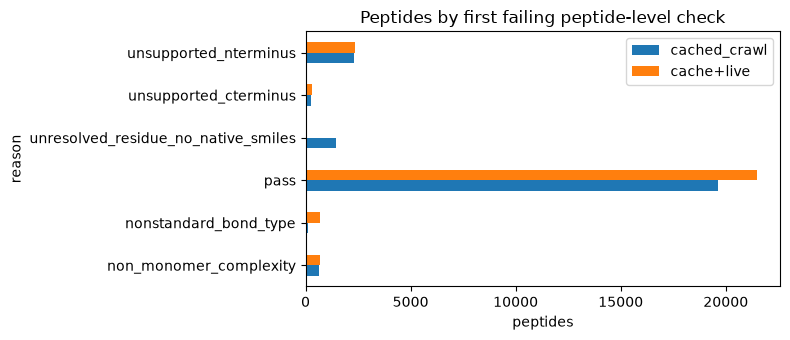

In [9]:
def eligibility(t):
    # eligible for the dataset = monomer AND (passes QMAP filter OR has a native SMILES -> recoverable)
    return t.monomer & (t.qmap_pass | t.native_smiles)
elig_cache, elig_now = eligibility(pt_cache), eligibility(pt_now)
print(f"eligible peptides (Monomer & (QMAP-pass | native SMILES)):  cache {elig_cache.sum():,}  ->  now {elig_now.sum():,}  "
      f"(+{elig_now.sum() - elig_cache.sum():,})")
gained = pt_now.index[elig_now & ~elig_now.index.isin(elig_cache.index[elig_cache])]
print(f"  of which newly eligible: {len(gained):,}  | new ids: {len(set(gained) & set(new_ids)):,}  | gained SMILES: {len(set(gained) & set(newly_smiles)):,}")

fig, ax = plt.subplots(figsize=(8, 3.5))
funnel.drop("TOTAL")[["cached_crawl", "cache+live"]].plot.barh(ax=ax)
ax.set_title("Peptides by first failing peptide-level check"); ax.set_xlabel("peptides"); plt.tight_layout()

### 3b. Can `p2smi` build a SMILES for peptides that still have none?

For monomers with no native SMILES, `smiles_gen.generate_smiles` (used in `05`/`06`) tries linear / disulfide / head-to-tail
construction and returns a reason when it cannot. Run on a capped sample (`P2SMI_LIMIT`) to keep the notebook fast.

In [10]:
P2SMI_LIMIT = 500
cand = pt_now.index[pt_now.monomer & ~pt_now.native_smiles][:P2SMI_LIMIT]
res = Counter()
for i in cand:
    p = DBAASPPeptide(merged[i])
    try:
        r = generate_smiles(p.sequence, p.unusual_amino_acids, p.intrachain_bonds, p.nterminus, p.cterminus)
        res["convertible" if r["convertible"] else f"fail: {r['reason'][:60]}"] += 1
    except Exception as e:
        res[f"exception: {type(e).__name__}"] += 1
print(f"sampled {len(cand)} of {int((pt_now.monomer & ~pt_now.native_smiles).sum()):,} monomers without native SMILES")
pd.Series(res).sort_values(ascending=False)

sampled 29 of 29 monomers without native SMILES


fail: 3 intrachain bonds present -- multi-bond (e.g. multiply-brid    7
convertible                                                           5
fail: 5 intrachain bonds present -- multi-bond (e.g. multiply-brid    4
fail: 4 intrachain bonds present -- multi-bond (e.g. multiply-brid    4
fail: 2 intrachain bonds present -- multi-bond (e.g. multiply-brid    2
fail: position 1 ('5-Br-Trp'): unknown residue code '5-Br-Trp': no    2
fail: position 1 ('P-Ser'): unknown residue code 'P-Ser': no match    1
fail: 7 intrachain bonds present -- multi-bond (e.g. multiply-brid    1
fail: DSB bond position 0 is outside the sequence (length 16) -- i    1
fail: position 62 ('Asn(GlcNAc) '): unknown residue code 'Asn(GlcN    1
fail: position 80 ('P-Ser'): unknown residue code 'P-Ser': no matc    1
dtype: int64

## 4. Activity-level filters (A1-A5) — waterfall

For every eligible peptide, each raw `targetActivities` record goes through (in this exact order, mirroring `06_assay_filter_units.py`):

* **A1** `activityMeasureGroup.name == "MIC"` — everything else (MBC, IC50, MIC50, MIC90, LC, MFC, `None`, ...) is dropped *first*.
* **A2** species domain is Bacteria. `species_binomial` keeps the first two words of the name (strain info dropped), `classify_genus` looks the genus up in NCBI taxonomy and checks the lineage for `Bacteria`.
* **A3** unit is `µM` or `µg/ml` (missing units and `nmol/g` can't be converted to molar concentration).
* **A4** SMILES resolved and RDKit MW computed (needed for µg/ml -> µM: `uM = 1000 * ug_ml / MW`).
* **A5** `parse_activity(concentration)` is not NaN. Parser rules: `a-b` range -> (a, b); `>X`/`>=X`/`≥X` -> (X, inf); `<X`/`<=X`/`up to X` -> (0, X); `v±e` -> (v-e, v+e); plain number -> (v, v); `NA`/empty -> NaN.

Then **T3**: group by (peptide, species binomial), drop IQR outliers when there are >= 4 bounds, average.
Here native SMILES is used for MW (peptides needing p2smi are not counted, so numbers are a slight lower bound vs. the pipeline).

In [11]:
_domain_cache = {}
def domain_of(name):
    if name not in _domain_cache:
        _domain_cache[name] = classify_species(name)
    return _domain_cache[name]

parse_errors = Counter()

def activity_funnel(peps: dict, ids):
    c = Counter(); groups = defaultdict(list); dropped_group = Counter(); dropped_unit = Counter(); dropped_dom = Counter()
    for i in ids:
        p = DBAASPPeptide(peps[i])
        smi = p.native_smiles_list[0] if p.has_native_smiles else None
        mw = compute_smiles_weight(smi) if smi else None
        for t in p.target_activities:
            c["0 all activity records"] += 1
            g = (t.get("activityMeasureGroup") or {}).get("name")
            if g != "MIC":
                dropped_group[g] += 1; continue
            c["1 A1 group == MIC"] += 1
            dom, taxid, binom = domain_of((t.get("targetSpecies") or {}).get("name"))
            if dom != "Bacteria":
                dropped_dom[dom] += 1; continue
            c["2 A2 Bacteria"] += 1
            unit = (t.get("unit") or {}).get("name")
            if unit not in ("µM", "µg/ml"):
                dropped_unit[unit] += 1; continue
            c["3 A3 unit uM or ug/ml"] += 1
            if smi is None or (unit == "µg/ml" and mw is None):
                continue
            c["4 A4 SMILES/MW available"] += 1
            try:
                lo, hi = parse_activity(t.get("concentration"))
            except ValueError:
                # parse_activity raises on strings like '0.03-<0.0625'; pipeline step 06 would crash here
                parse_errors[t.get("concentration")] += 1; continue
            if isinstance(lo, float) and math.isnan(lo):
                continue
            c["5 A5 concentration parseable"] += 1
            if unit == "µg/ml":
                lo, hi = ug_ml_to_uM(lo, hi, mw)
            groups[(i, binom)].append((lo, hi, classify_censoring(lo, hi, t.get("concentration"))))
    c["6 T3 unique (peptide, organism) pairs"] = len(groups)
    return c, groups, dropped_group, dropped_unit, dropped_dom

ids_cache = list(pt_cache.index[elig_cache]); ids_now = list(pt_now.index[elig_now])
f_cache, g_cache, *_ = activity_funnel(cache, ids_cache)
f_now, g_now, drop_group, drop_unit, drop_dom = activity_funnel(merged, ids_now)
wf = pd.DataFrame({"cached_crawl": f_cache, "cache+live": f_now}).sort_index()
wf["delta"] = wf["cache+live"] - wf["cached_crawl"]
display(wf)
print("concentration strings that make units.parse_activity RAISE (counted over both passes):", sum(parse_errors.values()))
print(parse_errors.most_common(10))

,cached_crawl,cache+live,delta
0 all activity records,163584,192654,29070
1 A1 group == MIC,115988,138959,22971
2 A2 Bacteria,104226,125244,21018
3 A3 unit uM or ug/ml,104203,125213,21010
4 A4 SMILES/MW available,103566,125098,21532
5 A5 concentration parseable,103562,125090,21528
"6 T3 unique (peptide, organism) pairs",72527,87997,15470


concentration strings that make units.parse_activity RAISE (counted over both passes): 2
[('0.3125-<0.0625', 2)]


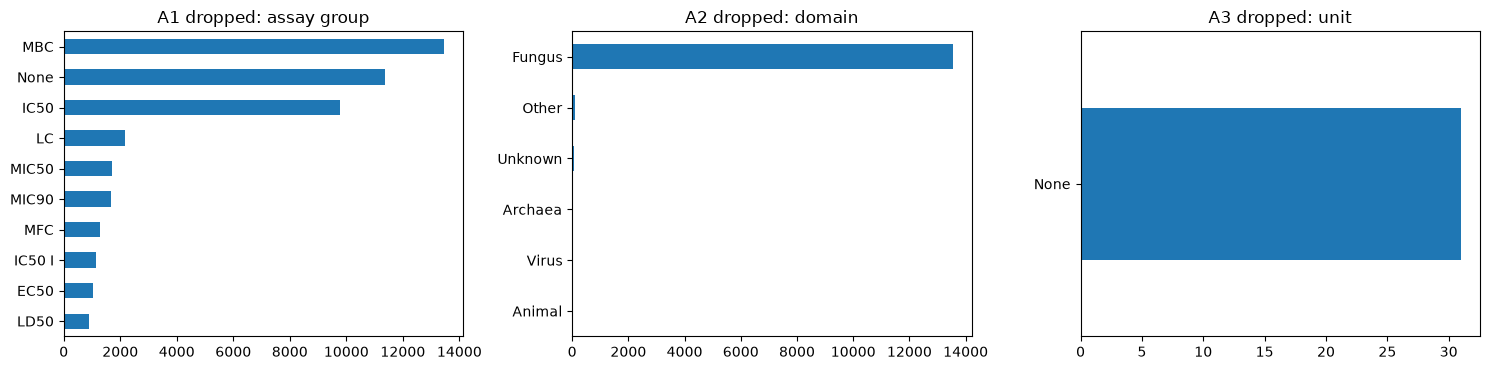

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, cnt) in zip(axes, [("A1 dropped: assay group", drop_group), ("A2 dropped: domain", drop_dom), ("A3 dropped: unit", drop_unit)]):
    s = pd.Series({str(k): v for k, v in cnt.items()}).sort_values(ascending=True).tail(10)
    s.plot.barh(ax=ax); ax.set_title(title)
plt.tight_layout()

In [13]:
final = pd.read_csv(FINAL_CSV)
print(f"current final dataset: {len(final):,} (peptide, organism) rows, {final.peptide_id.nunique():,} peptides")
print(f"re-derived pairs here (native-SMILES peptides only, cache+live): {len(g_now):,}")
pairs_final = set(zip(final.peptide_id.astype(int), final.organism))
new_pairs = set(g_now) - pairs_final
print(f"pairs here that are NOT in the current final dataset: {len(new_pairs):,}  "
      f"(from new ids: {sum(1 for p, _ in new_pairs if p in set(new_ids)):,})")

current final dataset: 72,587 (peptide, organism) rows, 15,904 peptides
re-derived pairs here (native-SMILES peptides only, cache+live): 87,997
pairs here that are NOT in the current final dataset: 15,424  (from new ids: 5,102)


## 5. Active / not-active records **without an MIC**

Rule **A1** keeps only `activityMeasureGroup == "MIC"`. But DBAASP stores a family of qualitative results with
`activityMeasureGroup = null`: `concentration = "NA"`, `activityMeasureValue` `"-"` or empty, `unit = null`, the numeric `activity`
field set to the sentinel **1111111.0**, and the actual result only in the free-text **`note`** (e.g. *"Not active up to 100 µM"*).
A5 would also reject them (`NA` -> NaN), but A1 removes them first, so they never show up in any drop counter downstream.

Below we isolate them, classify the note, and measure what the pipeline is missing. Semantics of *"Not active up to X"*: no activity was
seen at the highest tested concentration X, i.e. MIC > X — the same right-censored information as an MIC reported as `>X` (which `parse_activity` already turns into `(X, inf)`).

In [14]:
def is_qualitative(t):
    g = (t.get("activityMeasureGroup") or {}).get("name")
    return g is None

rows = []
for i in ids_now:
    p = DBAASPPeptide(merged[i])
    for t in p.target_activities:
        if not is_qualitative(t):
            continue
        dom, taxid, binom = domain_of((t.get("targetSpecies") or {}).get("name"))
        rows.append({"peptide_id": i, "species": (t.get("targetSpecies") or {}).get("name"), "binomial": binom, "domain": dom,
                     "concentration": t.get("concentration"), "value": t.get("activityMeasureValue"),
                     "unit": (t.get("unit") or {}).get("name"), "activity_num": t.get("activity"),
                     "note": (t.get("note") or "").strip()})
q = pd.DataFrame(rows)
print(f"qualitative (group=None) records among eligible peptides: {len(q):,}")
print("sentinel activity==1111111:", int((q.activity_num == 1111111).sum()), "| concentration=='NA':", int((q.concentration == 'NA').sum()))
q["note_pattern"] = q.note.str.replace(r"[\d.,]+", "<N>", regex=True).str.replace(r"\s+", " ", regex=True)
q.note_pattern.value_counts().head(25)

qualitative (group=None) records among eligible peptides: 11,381
sentinel activity==1111111: 11342 | concentration=='NA': 11352


note_pattern
                                                                 3091
Not active up to <N> µM                                          2577
Not active up to <N> µg/ml                                       1602
Not active up to <N> micro M                                      344
Not active at <N> µg/ml                                           209
Not active                                                        179
Not active at <N> µM                                              165
Not active up to <N> μM                                           164
Not active at <N> micro M                                         112
Not active up to <N> micro g/ml                                   101
Clinical isolate                                                   98
No activity at <N> nmol peptide per well                           95
Not active up to <N> µg/ml; clinical isolate                       87
Not active at <N> micro g/ml                                       85
Not act

In [15]:
NEG = re.compile(r"not\s+active|inactive|no\s+(?:\w+\s+){0,2}(?:activity|inhibition|clear zone)|almost not active", re.I)
THR = re.compile(r"(?:up\s+to|at(?:\s+a\s+concentration)?|<=|>=|>|<)\s*>?\s*([\d]+(?:[.,]\d+)?)\s*(m\s?M|mM|µ\s?M|μ\s?M|u\s?M|micro\s*M|µ?g\s*/\s*m[lL]|μg\s*/\s*m[lL]|micro\s*g\s*/\s*m[lL]|ug\s*/\s*m[lL])", re.I)
POS = re.compile(r"^(?:highly |weakly |moderately |slightly )?active\b", re.I)

def classify_note(n):
    # -> (label_kind, threshold value, unit). Negation is searched ANYWHERE in the note, because DBAASP prefixes
    # strain info ('Clinical isolate; Not active up to 64 ug/ml').
    if not n:
        return "empty_note", None, None
    if NEG.search(n):
        m = THR.search(n)
        if not m:
            return "not_active_no_threshold", None, None
        val = float(m.group(1).replace(",", "."))
        u = m.group(2).lower().replace(" ", "")
        if "g/ml" in u:
            return "not_active_with_threshold", val, "ug/ml"
        if u == "mm":
            return "not_active_with_threshold", val * 1000, "uM"
        return "not_active_with_threshold", val, "uM"
    if POS.match(n):
        return "positive_active", None, None
    return "other", None, None

cl = q.note.apply(classify_note)
q["label_kind"] = [c[0] for c in cl]; q["thr"] = [c[1] for c in cl]; q["thr_unit"] = [c[2] for c in cl]
print(q.label_kind.value_counts().to_string())
print()
print("threshold units:", q[q.label_kind == "not_active_with_threshold"].thr_unit.value_counts().to_dict())

label_kind
not_active_with_threshold    6990
empty_note                   3091
other                         827
not_active_no_threshold       473

threshold units: {'uM': 4206, 'ug/ml': 2784}


In [16]:
# Anything that is NOT a negation: are there POSITIVE ('active') labels with no MIC? (look at 'positive_active' count above and the leftovers here)
q[~q.label_kind.isin(["not_active_with_threshold", "not_active", "empty_note"])].note_pattern.value_counts().head(20)

note_pattern
Not active                                                             179
Clinical isolate                                                        98
No activity at <N> nmol peptide per well                                95
clinical isolate                                                        69
MRSA                                                                    43
MDR                                                                     41
by radial diffusion assay                                               32
MRSA subsp<N> strain                                                    27
In disc diffusion assay                                                 27
Grouper V<N> alginolyticus                                              25
Not active up to <N> nano M                                             21
VRE                                                                     20
New Delhi metallo-beta-lactamase (NDM) resistant                        19
Not active u

In [17]:
# Convert thresholds to uM (ug/ml via RDKit MW from native SMILES), restrict to bacteria
def thr_uM(row):
    if row.thr is None or (isinstance(row.thr, float) and math.isnan(row.thr)):
        return np.nan
    if row.thr_unit == "uM":
        return row.thr
    if row.thr_unit == "ug/ml":
        p = DBAASPPeptide(merged[row.peptide_id])
        if not p.has_native_smiles:
            return np.nan
        mw = compute_smiles_weight(p.native_smiles_list[0])
        return 1000 * row.thr / mw if mw else np.nan
    return np.nan

qb = q[q.domain == "Bacteria"].copy()
qb["threshold_uM"] = qb.apply(thr_uM, axis=1)
print(f"bacterial qualitative records: {len(qb):,} of {len(q):,}")
print(qb.groupby("label_kind").agg(records=("peptide_id", "size"), peptides=("peptide_id", "nunique"),
                                   convertible_to_uM=("threshold_uM", lambda s: int(s.notna().sum()))))

bacterial qualitative records: 8,354 of 11,381
                           records  peptides  convertible_to_uM
label_kind                                                     
empty_note                    2424       696                  0
not_active_no_threshold        335        89                  0
not_active_with_threshold     4972      1375               4972
other                          623       268                  0


qualitative (peptide, organism) pairs           : 7,572
  already have an MIC row in final dataset      : 436
  have a usable MIC re-derived here             : 464
  ONLY qualitative (genuinely new pairs)        : 7,108  across 2,023 peptides, 297 organisms
  of which peptides absent from final dataset   : 1,090


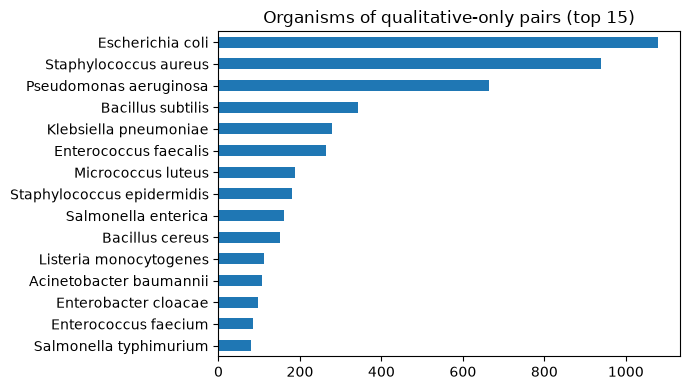

In [18]:
# How many (peptide, organism) pairs would this ADD, versus what the dataset already has?
qpairs = set(zip(qb.peptide_id, qb.binomial))
in_mic_now = set(g_now)               # pairs that have a usable MIC (this notebook's re-derivation)
in_final = pairs_final
print(f"qualitative (peptide, organism) pairs           : {len(qpairs):,}")
print(f"  already have an MIC row in final dataset      : {len(qpairs & in_final):,}")
print(f"  have a usable MIC re-derived here             : {len(qpairs & in_mic_now):,}")
only_q = qpairs - in_mic_now - in_final
print(f"  ONLY qualitative (genuinely new pairs)        : {len(only_q):,}  across {len({p for p, _ in only_q}):,} peptides, {len({o for _, o in only_q}):,} organisms")
print(f"  of which peptides absent from final dataset   : {len({p for p, _ in only_q} - set(final.peptide_id.astype(int))):,}")

top = pd.Series(Counter(o for _, o in only_q)).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4)); top[::-1].plot.barh(ax=ax); ax.set_title("Organisms of qualitative-only pairs (top 15)"); plt.tight_layout()

In [19]:
# Pairs with BOTH a qualitative 'not active' and an MIC row — do they agree?
# CAVEAT: pairs are keyed on the species BINOMIAL, so strains are pooled. Notes like 'Clinical isolate' / 'MRSA' / 'VRE' / 'MDR'
# mean the negative result was for a resistant strain while the MIC row may come from the susceptible reference strain.
# Disagreement is therefore expected and is NOT a data error -- it shows why these records need strain-aware handling.
both = qpairs & in_final
fin = final.assign(peptide_id=final.peptide_id.astype(int)).set_index(["peptide_id", "organism"])
chk = []
for (pid, org) in both:
    for _, r in qb[(qb.peptide_id == pid) & (qb.binomial == org)].iterrows():
        if r.label_kind in ("not_active_with_threshold",) and pd.notna(r.threshold_uM):
            mic = fin.loc[(pid, org), "mic_value_uM"]
            mic = float(mic.iloc[0] if hasattr(mic, "iloc") else mic)
            chk.append({"peptide_id": pid, "organism": org, "mic_uM": mic, "not_active_up_to_uM": r.threshold_uM,
                        "consistent": mic >= r.threshold_uM * 0.999})
chk = pd.DataFrame(chk)
print(f"{len(chk)} comparable pairs; MIC >= 'not active up to' threshold in {chk.consistent.mean():.1%}" if len(chk) else "no comparable pairs")
chk[~chk.consistent].head(10) if len(chk) else None

395 comparable pairs; MIC >= 'not active up to' threshold in 21.0%


,peptide_id,organism,mic_uM,not_active_up_to_uM,consistent
1,8432,Klebsiella pneumoniae,1.95,38.983710,False
2,5605,Escherichia coli,53.10,106.244663,False
3,5605,Escherichia coli,53.10,106.244663,False
4,11252,Pseudomonas aeruginosa,26.70,256.000000,False
6,9797,Bacillus thuringiensis,4.00,250.000000,False
7,9797,Bacillus thuringiensis,4.00,250.000000,False
8,18812,Staphylococcus aureus,25.30,64.000000,False
9,8428,Escherichia coli,32.90,89.820225,False
11,8432,Staphylococcus aureus,1.95,38.983710,False
12,8432,Staphylococcus aureus,1.95,38.983710,False


## 6. Summary and what a pipeline change would need

* **Live API** returns the full card (49 keys) and the activities list; ids now go well beyond the 24,707 limit baked into `config/curation/base.yaml` (`max_id` + `id_margin`) — the crawl needs a larger range or an open-ended probe (as done in section 2).
* **New SMILES** matter because check P4 only excludes unresolved residues when there is *no* native SMILES; peptides that gained one become eligible directly, with MW from RDKit. Sections 2-3 quantify this (cached no-SMILES peptides that gained a SMILES, and brand-new ids).
* **Parser robustness**: `units.parse_activity` raises `ValueError` on some strings (e.g. `0.03-<0.0625`); section 4 lists them. Step `06` has no guard, so a re-run on fresh data would crash there.
* **Qualitative "Not active" records** are dropped by A1 (their group is `null`). They carry real information (MIC > X) for exactly the (peptide, organism) pairs that are currently missing, and they are *inactive* labels only — the minority class in the current data (see CLAUDE.md: ~84% active). Section 5 counts them.
* If you want them in: add a parser path before A1 that maps `group is None` + note `"Not active up to X [unit]"` to a censored `(X, inf)` bound (µg/ml via RDKit MW), tag it with a new source/`mic_type` (e.g. `qualitative_censored`) so labeling can treat it as `inactive` when `X >= inactive_threshold_uM` and `uncertain` otherwise; a bare `"Not active"` / empty note has no concentration and cannot be thresholded (the bare cases are counted in section 5). Section 5 finds **no positive 'active' record without an MIC**: every note containing the word 'active' is a negation (e.g. 'Clinical isolate; Not active up to …'). The asymmetry matters — adding these records adds only inactive-side evidence, so it would push class balance further away from the current ~84% active; strain qualifiers (clinical isolate/MRSA/VRE/MDR) are pooled by the binomial key and should be considered before use.

## 7. Handoff notes (written 2026-10-17, end of the slide-deck session)

**Slide deck built from this notebook's findings:** `presentations/dbaasp_filtering_walkthrough.tex` (+ `.pdf`, compile with `tectonic`). All counts and worked examples are generated by `scripts/slides/build_curation_facts.py` from `reports/step*_log.txt` and `data/*.csv` (outputs: `presentations/generated/curation_{facts,examples}.tex`, `parse_table.tex`, `reports/slide_figs/d1_*.png`, `d2_*.png`). Re-run it after any pipeline re-run. QMAP quotes come from `presentations/QMAP.pdf` (Sci. Rep. 16:25387, Methods).

**Open preprocessing issues found (none fixed yet):**
1. `parse_activity` crashes on `0.3125-<0.0625` (2 raw cases); `06_assay_filter_units.py` has no try/except, so a re-run on fresh data dies there.
2. `config/curation/base.yaml` `crawl.max_id` (24207) + `id_margin` (500) is stale: live DBAASP has ~1,105 more ids and 3,404 cached peptides gained a native SMILES. The final dataset is behind live data (15,424 re-derived pairs missing, 5,102 from new ids).
3. 7,108 (peptide, organism) pairs exist only as qualitative "not active up to X" records (`activityMeasureGroup` is null). They are inactive-side evidence only; adding them worsens the ~84% active imbalance. Decision pending (see section 6 for the proposed `qualitative_censored` path).
4. Single-row ranges such as `"11-15"` are labelled `mic_type = 'censored'` in step 06 (a two-sided interval collapsed into the censored class). Labeling handles it via recovered bounds, but the name is misleading.
5. QMAP's published file is pre-aggregated per species ([min, max, mean] in uM). We re-derive from raw rows with RDKit MW from the full SMILES, so values differ slightly (peptide 10 *S. aureus*: QMAP 16.0 vs ours 15.6; QMAP's numbers imply MW about 815 vs RDKit 832.1).
6. Stale docs: `reports/curation_audit.md` / `qa_report.md` still cite `scripts/01-08_*.py`; the code is in `pipeline/curation/` and `src/soamp/curation/`.

**Reference numbers (pipeline logs, not this notebook's native-SMILES-only subset):** 24,444 crawled -> 664 non-monomer, 2,565 terminus, 1,428 residue-no-SMILES, 135 bond -> 19,652 pass (18,033 in QMAP + 1,619 not). Recovery: 5,747 retried, 2,870 recovered. Activity rows: 163,653 -> 103,629 kept (-47,604 non-MIC, -11,766 non-bacterial, -23 unit, -627 no MW, -4 unparseable) -> 72,587 (peptide, species) pairs. Notebook 08 numbers differ by ~60 pairs / 17 peptides because it ignores p2smi-recovered peptides.

**Not verified:** the 2-peptide gap between the pipeline's 19,652 and this notebook's 19,650 passing peptides; QMAP's own raw-pull size (not published).
